### Обработка данных фотометрии, полученных от хлорчувствительной мыши

## Этап 1: выгрузка данных

В результате работы по фотометрии нейронов зоны Insula Cortex были получены данные в формате .csv. Основные 3 файла: events, fluorescence-unaligned и fluorescence – исходные, получены от сенсора прибора и представлены ниже. 
> В набор данных также входили .csv файлы содержавшие z-score и dff оценку полученных результатов.

In [2]:
from dotenv import load_dotenv
from pathlib import Path
import pandas as pd

load_dotenv(Path.cwd().parent/".env")

df = pd.read_csv("/Users/ivan/Downloads/2026_03_10-16_56_33/Events.csv")
print(f"{df.head(7)}"+"\n")

df1=pd.read_csv("/Users/ivan/Downloads/2026_03_10-16_56_33/Fluorescence.csv")
print(f"{df1.head(7)}"+"\n")

df2=pd.read_csv("/Users/ivan/Downloads/2026_03_10-16_56_33/Fluorescence-unaligned.csv")
print(f"{df2.head(7)}"+"\n")


     TimeStamp    Name  State
0   644894.409  Event1      0
1   645017.503  Event1      1
2  1083171.341  Event2      0
3  1083459.886  Event2      1
4  1503451.024  Event3      0
5  1503628.594  Event3      1

                                          {"Light":{"Led410Enable":true;"Led470Enable":true;"Led560Enable":true;"Led410Value":100.0;"Led470Value":100.0;"Led560Value":84.999999999999886};"Excitation":{"mode":3;"discontinuous":false;"interval_time":1;"continuous_time":1};"Channels":[{"Name":"CH1";"Roi1":"305.670422535211;227;102.304225352113;102.304225352113";"Roi2":"312.847887323943;220.847887323943;102.304225352113;102.304225352113"}];"AllMarking":[{"id":0;"type":1;"opened":true;"name":"Event1";"Levels":0;"color":"#FF0099FF";"key":0;"threshold":0.0;"all":true;"channels":[];"enable":true};{"id":0;"type":1;"opened":true;"name":"Event2";"Levels":0;"color":"#FF0099FF";"key":0;"threshold":0.0;"all":true;"channels":[];"enable":true};{"id":0;"type":1;"opened":true;"name":"Event3";"Leve

В данных .csv файлах видно, что событие 1, 2 и 3 занимали по продолжительности 0.12с, 0.29с и 0.18с соответственно. 

> Ввиду того, что при проведении эксперимента по протоколу шок занимал 1 секунду времени в каждом из событий, в дальнейшем рамки событий расширены от миллисекунд до 1 секунды, что будет видно на графиках ниже.

## Этап 2: визуализация данных

На данном этапе мы провели графическую визуализацию первичных данных с наложением на них временных рамок событий 1, 2 и 3.

In [3]:
import pandas as pd

df = pd.read_csv("/Users/ivan/Downloads/2026_03_10-16_56_33/Fluorescence-unaligned.csv")
df410 = df.loc[df["Lights"] == 410, ["TimeStamp", "Channel1"]]
df410["Time_seconds"] = df410["TimeStamp"] / 1000
print(df410.head(7))

    TimeStamp  Channel1  Time_seconds
0       0.000   406.327      0.000000
3      49.979   406.383      0.049979
6      99.959   406.629      0.099959
9     149.938   406.465      0.149938
12    199.918   406.445      0.199918
15    249.897   406.472      0.249897
18    299.876   406.338      0.299876


Здесь мы извлекли из необработанного Fluorescence-unaligned.csv данные по 410 нм для визуализации ниже. Этот же процесс произведем с 470 и 560 нм.

In [16]:
import pandas as pd

df = pd.read_csv("/Users/ivan/Downloads/2026_03_10-16_56_33/Fluorescence-unaligned.csv")
df470 = df.loc[df["Lights"] == 470, ["TimeStamp", "Channel1"]]
df470["Time_seconds"] = df470["TimeStamp"] / 1000
print(f"{df470.head(7)}"+"\n")

df = pd.read_csv("/Users/ivan/Downloads/2026_03_10-16_56_33/Fluorescence-unaligned.csv")
df560 = df.loc[df["Lights"] == 560, ["TimeStamp", "Channel1"]]
df560["Time_seconds"] = df560["TimeStamp"] / 1000
print(df560.head(7))

    TimeStamp  Channel1  Time_seconds
1      16.660   184.681      0.016660
4      66.639   184.614      0.066639
7     116.619   184.779      0.116619
10    166.598   184.769      0.166598
13    216.578   184.584      0.216578
16    266.557   184.658      0.266557
19    316.539   184.562      0.316539

    TimeStamp  Channel1  Time_seconds
2      33.332   202.797      0.033332
5      83.312   202.542      0.083312
8     133.291   202.588      0.133291
11    183.271   202.579      0.183271
14    233.250   202.628      0.233250
17    283.230   202.702      0.283230
20    333.209   202.540      0.333209


### Визуализация трех графиков: 410, 470 и 560нм

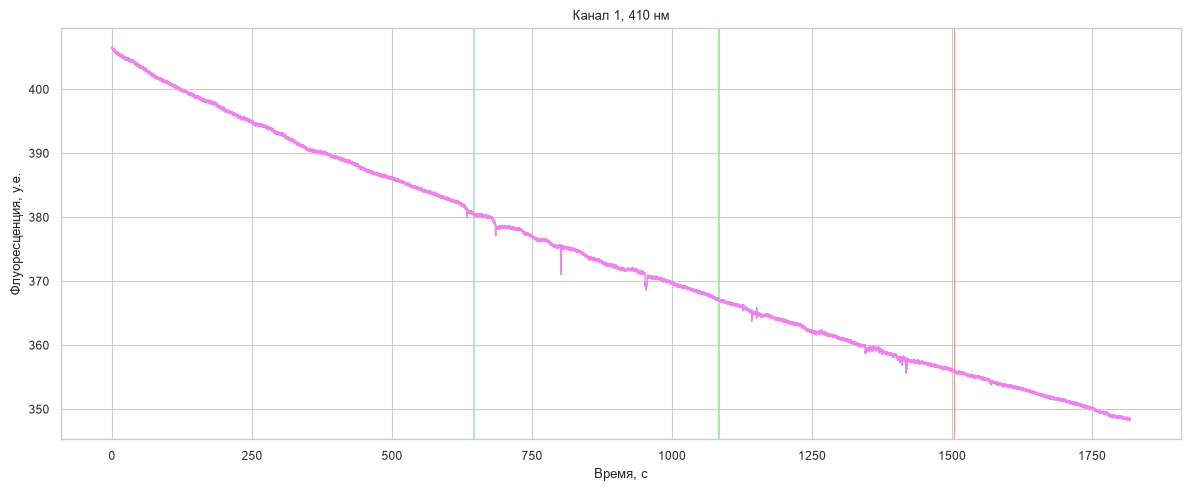

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt

events = pd.read_csv("/Users/ivan/Downloads/2026_03_10-16_56_33/Events.csv")

ev = events.pivot(index = "Name", columns = "State", values = "TimeStamp") / 1000
ev.columns = ["start", "end"]
ev["start"] -= 0.5
ev["end"] += 0.5

event_colors = ["lightblue", "lightgreen", "lightcoral"]

sns.set_theme(context="paper", style = "whitegrid")

fig, ax = plt.subplots(figsize = (12, 5))
sns.lineplot(data = df410, x = "Time_seconds", y = "Channel1", color = "violet", linewidth = 1, ax=ax)

for (name, row), c in zip(ev.iterrows(), event_colors):
    ax.axvspan(row["start"], row["end"], color=c, alpha=0.8, label=name)

ax.set_title("Канал 1, 410 нм")
ax.set_xlabel("Время, c")
ax.set_ylabel("Флуоресценция, у.е.")

plt.tight_layout()
plt.show()

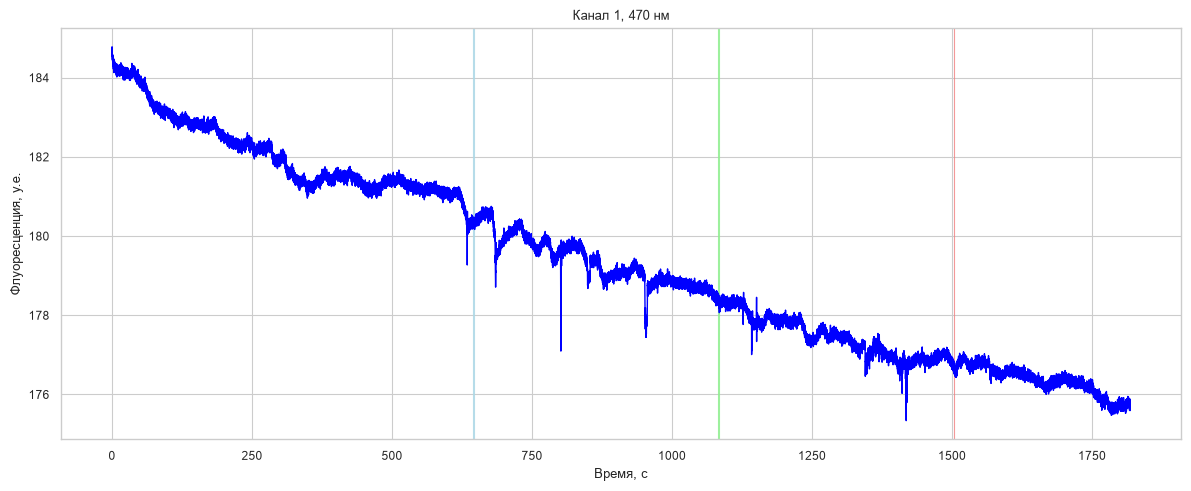

In [72]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(context="paper", style = "whitegrid")

fig, ax = plt.subplots(figsize = (12, 5))
sns.lineplot(data = df470, x = "Time_seconds", y = "Channel1", color = "blue", linewidth = 1, ax=ax)

for (name, row), c in zip(ev.iterrows(), event_colors):
    ax.axvspan(row["start"], row["end"], color=c, alpha=0.8, label=name)

ax.set_title("Канал 1, 470 нм")
ax.set_xlabel("Время, c")
ax.set_ylabel("Флуоресценция, у.е.")

plt.tight_layout()
plt.show()

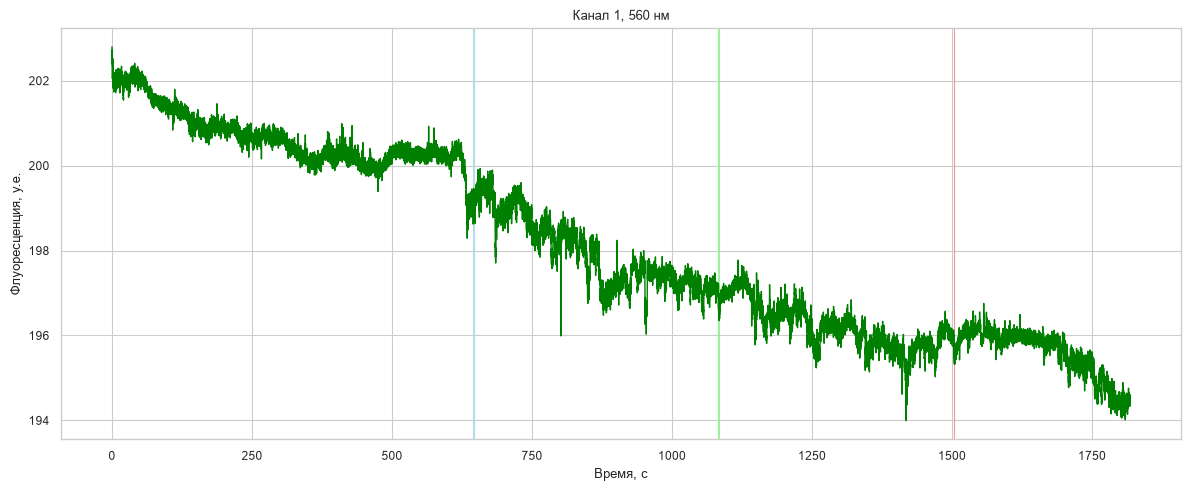

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(context="paper", style = "whitegrid")

fig, ax = plt.subplots(figsize = (12, 5))
sns.lineplot(data = df560, x = "Time_seconds", y = "Channel1", color = "green", linewidth = 1, ax=ax)

for (name, row), c in zip(ev.iterrows(), event_colors):
    ax.axvspan(row["start"], row["end"], color=c, alpha=0.8, label=name)

ax.set_title("Канал 1, 560 нм")
ax.set_xlabel("Время, c")
ax.set_ylabel("Флуоресценция, у.е.")

plt.tight_layout()
plt.show()

Представленные выше графики включают все 3 события шока, но для их детального анализа необходимо снизить масштаб.

### Детализация ответа на шок

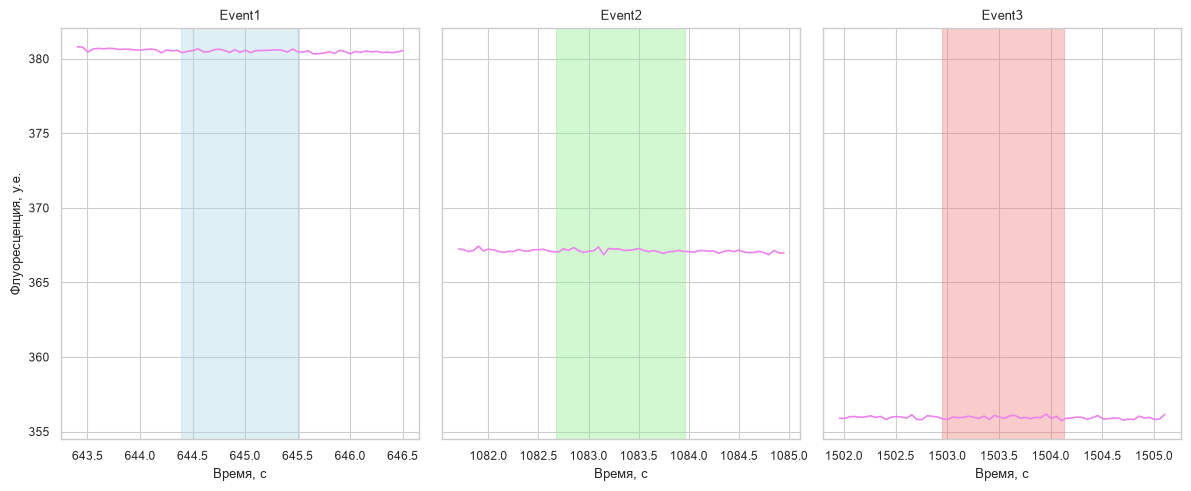

In [75]:
fig, axes = plt.subplots(1, 3, figsize=(12,5), sharey=True)

for ax, (name, row), ec in zip(axes, ev.iterrows(), event_colors):
    part = df410[df410["Time_seconds"].between(row["start"] - 1, row["end"] + 1)]

    sns.lineplot(data=part, x="Time_seconds", y="Channel1", color="violet", ax=ax)
    ax.axvspan(row["start"], row["end"], color=ec, alpha=0.4)

    ax.set_title(name)
    ax.set_xlabel("Время, с")

axes[0].set_ylabel("Флуоресценция, у.е.")
plt.tight_layout()
plt.show()

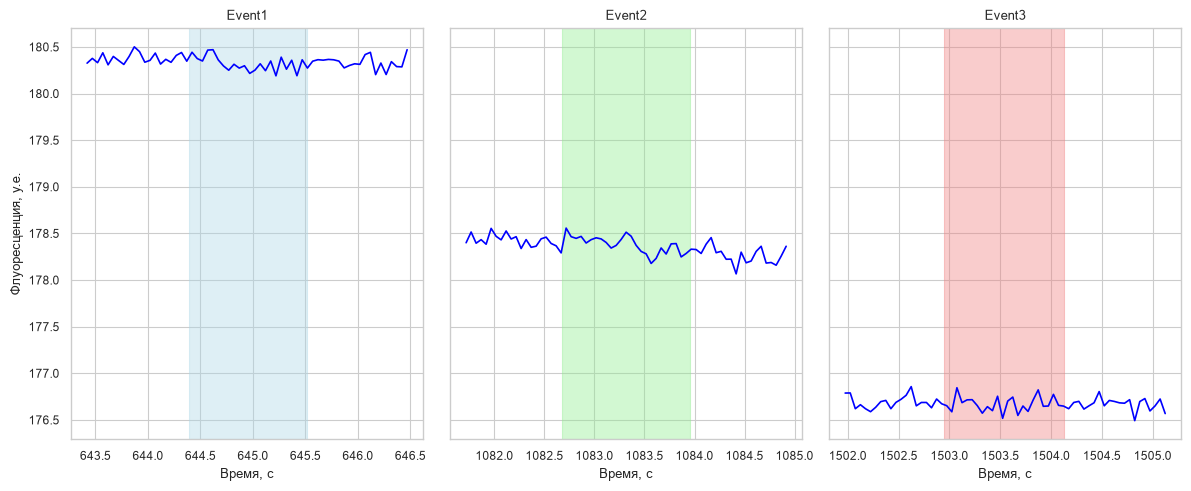

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(12,5), sharey=True)

for ax, (name, row), ec in zip(axes, ev.iterrows(), event_colors):
    part = df470[df470["Time_seconds"].between(row["start"] - 1, row["end"] + 1)]

    sns.lineplot(data=part, x="Time_seconds", y="Channel1", color="blue", ax=ax)
    ax.axvspan(row["start"], row["end"], color=ec, alpha=0.4)

    ax.set_title(name)
    ax.set_xlabel("Время, с")

axes[0].set_ylabel("Флуоресценция, у.е.")
plt.tight_layout()
plt.show()

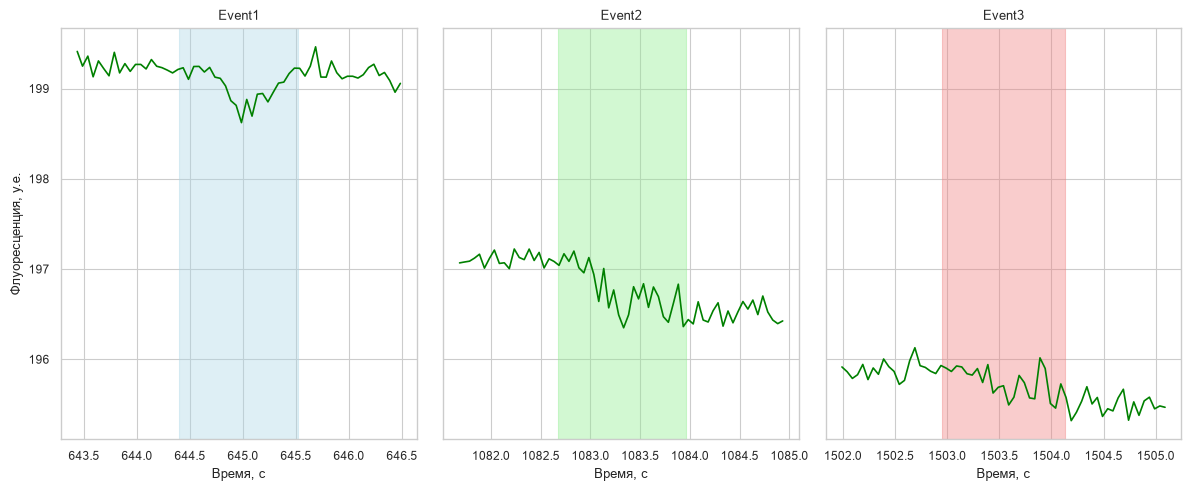

In [77]:
fig, axes = plt.subplots(1, 3, figsize=(12,5), sharey=True)

for ax, (name, row), ec in zip(axes, ev.iterrows(), event_colors):
    part = df560[df560["Time_seconds"].between(row["start"] - 1, row["end"] + 1)]

    sns.lineplot(data=part, x="Time_seconds", y="Channel1", color="green", ax=ax)
    ax.axvspan(row["start"], row["end"], color=ec, alpha=0.4)

    ax.set_title(name)
    ax.set_xlabel("Время, с")

axes[0].set_ylabel("Флуоресценция, у.е.")
plt.tight_layout()
plt.show()

### Нормализация данных

На графиках выше заметна тенденция к спаду флюоресценции во времени не зависимо от наличия электрического шока. Данный феномен можно объяснить выцветанием. 
> Для компенсации из значения каждой точки можно вычесть значение экспоненты спада в данной точке и поделить разность на него же: дельтаF/F (или dFF) – бисэкпонента. 

Таким образом мы получим прямой график, на котором будут лучше видны реактивные изменения значений.

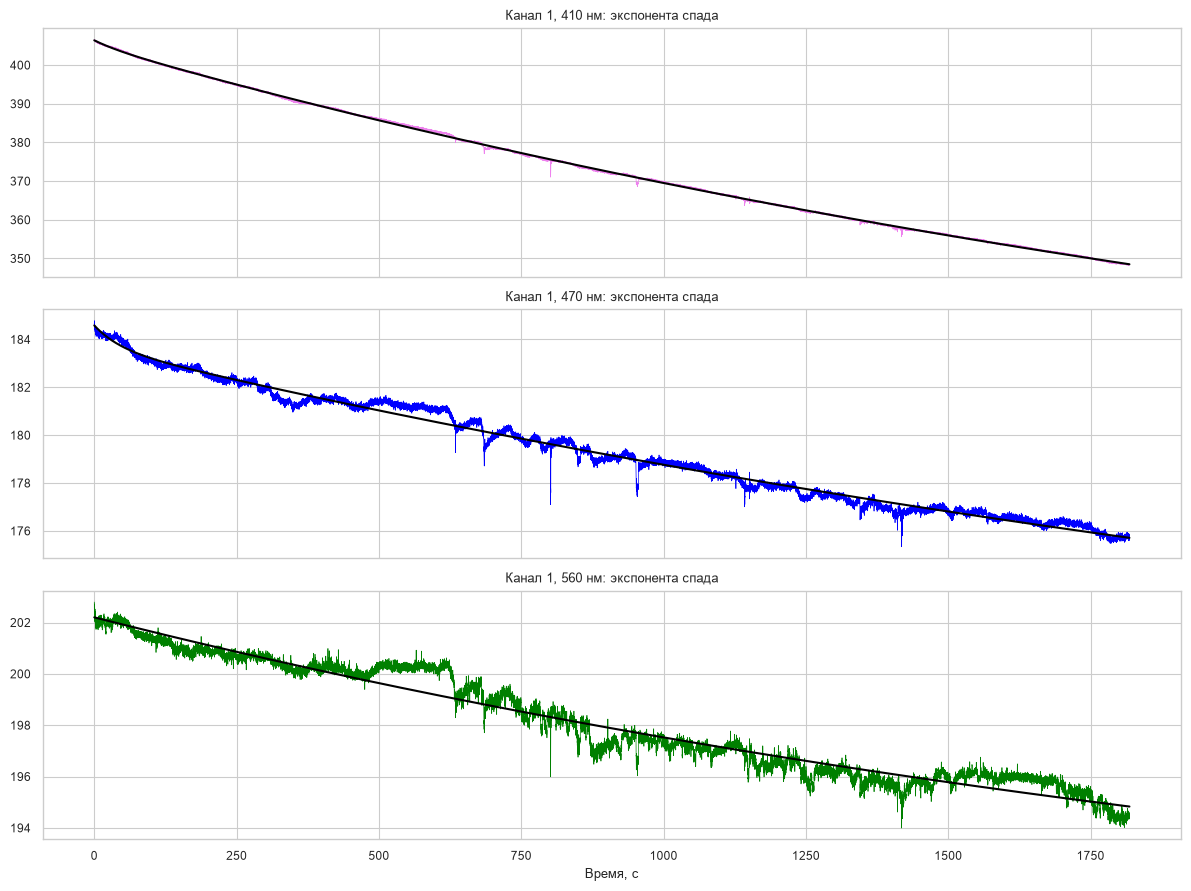

In [78]:
import numpy as np
from scipy.optimize import curve_fit

def biexp(t, a, tau1, b, tau2, c):
    return a*np.exp(-t/tau1)+b*np.exp(-t/tau2)+c

def normalize(d):
    t = d["Time_seconds"].values
    y = d["Channel1"].values

    mask = np.ones_like(t, dtype=bool)
    for _, row in ev.iterrows():
        mask &= ~((t >= row["start"] - 5) & (t <= row["end"] + 30))


    amp = max(y[0] - y[-1], 1)
    p0 = [amp / 2, 60, amp / 2, 1000, y[-1]]
    bounds = ([0, 5, 0, 5, 0], [np.inf, 1e5, np.inf, 1e5, np.inf])
    p, _ = curve_fit(biexp, t[mask], y[mask], p0 = p0, bounds = bounds, maxfev = 20000)

    d = d.copy()
    d["fit"] = biexp(t, *p)
    d["dFF"] = (y - d["fit"]) / d["fit"] * 100
    return d

df410 = normalize(df410)
df470 = normalize(df470)
df560 = normalize(df560)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (d, c, wl) in zip(axes, [(df410, "violet", 410), (df470, "blue", 470), (df560, "green", 560)]):
    ax.plot(d["Time_seconds"], d["Channel1"], color=c, lw=0.5)
    ax.plot(d["Time_seconds"], d["fit"], color="black", lw=1.5)
    ax.set_title(f"Канал 1, {wl} нм: экспонента спада")
axes[-1].set_xlabel("Время, с")
plt.tight_layout()
plt.show()


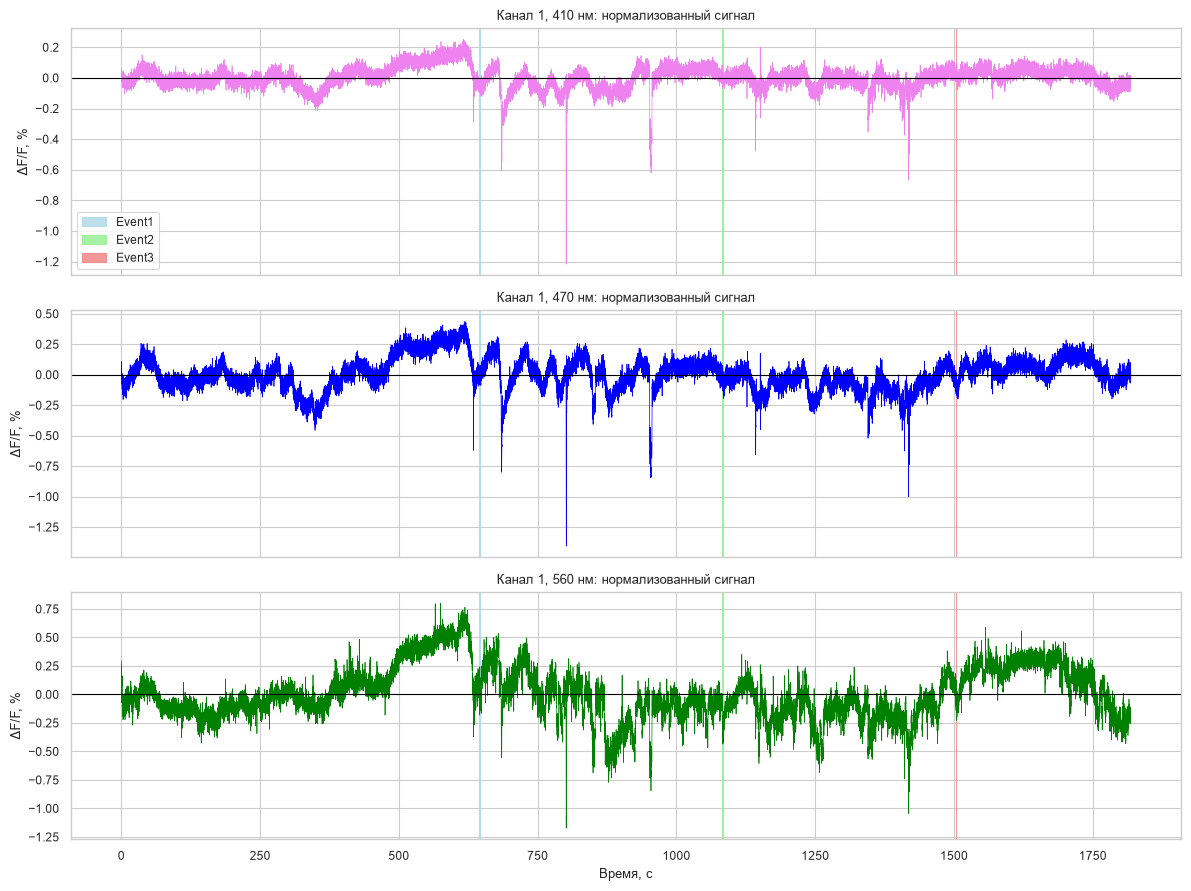

In [80]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (d, c, wl) in zip(axes, [(df410, "violet", 410), (df470, "blue", 470), (df560, "green", 560)]):
    ax.plot(d["Time_seconds"], d["dFF"], color=c, lw=0.5)
    ax.axhline(0, color="black", lw=0.8)
    for (name, row), ec in zip(ev.iterrows(), event_colors):
        ax.axvspan(row["start"], row["end"], color=ec, alpha=0.8, label=name)
    ax.set_title(f"Канал 1, {wl} нм: нормализованный сигнал")
    ax.set_ylabel("ΔF/F, %")
axes[0].legend()
axes[-1].set_xlabel("Время, с")
plt.tight_layout()
plt.show()

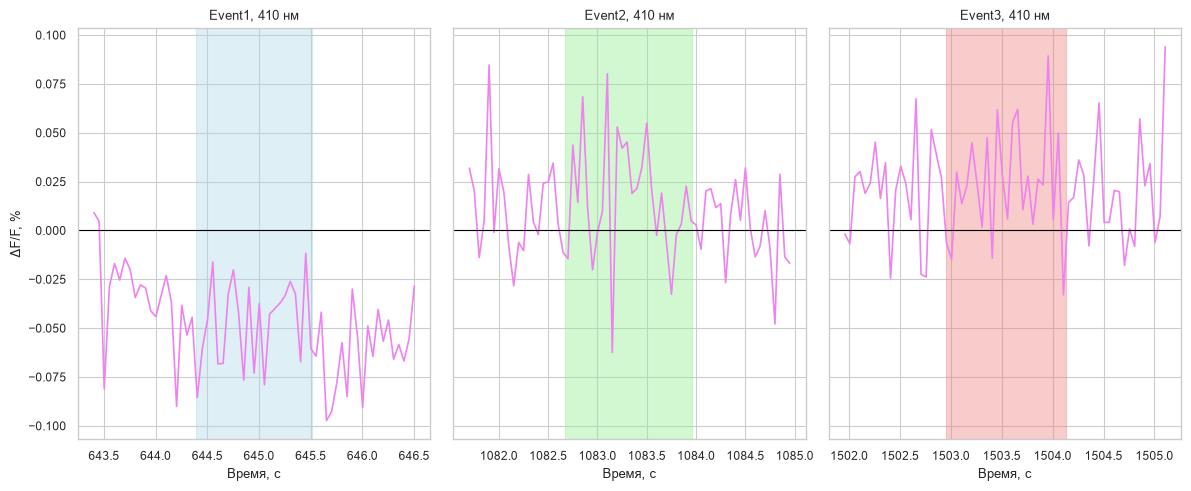

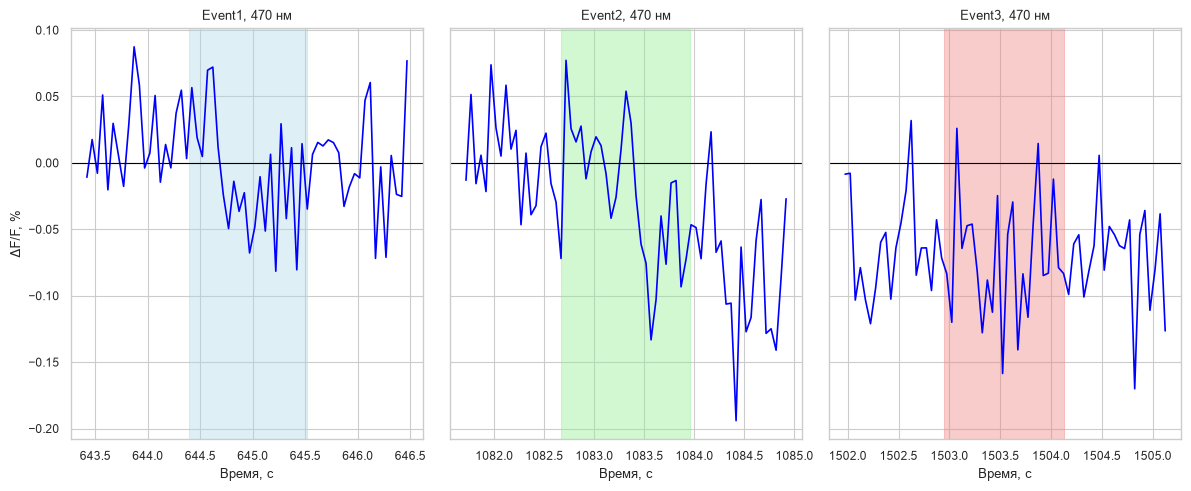

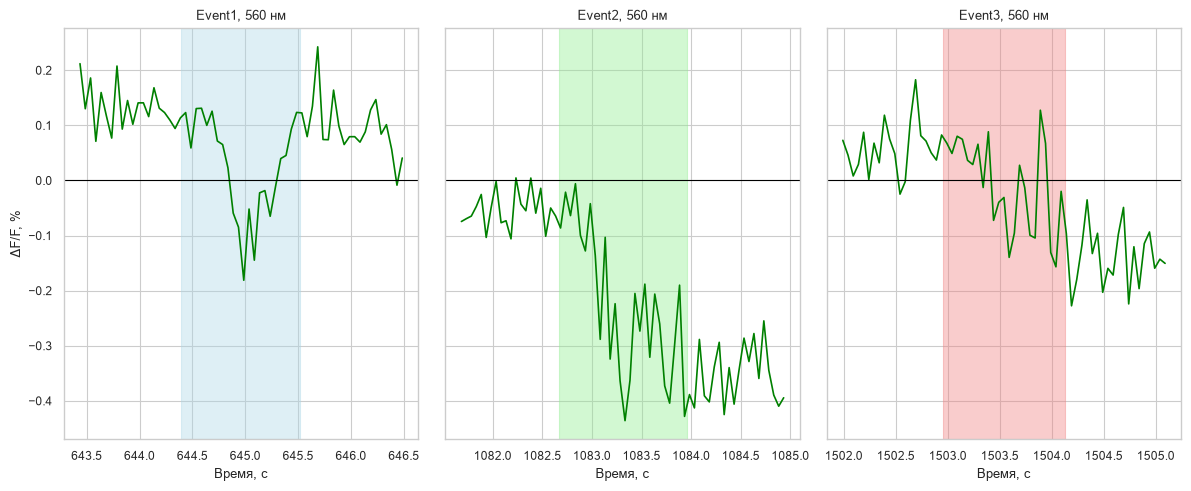

In [81]:
for d, c, wl in [(df410, "violet", 410), (df470, "blue", 470), (df560, "green", 560)]:
    fig, axes = plt.subplots(1, 3, figsize=(12, 5), sharey=True)
    for ax, (name, row), ec in zip(axes, ev.iterrows(), event_colors):
        part = d[d["Time_seconds"].between(row["start"] - 1, row["end"] + 1)]
        sns.lineplot(data=part, x="Time_seconds", y="dFF", color=c, ax=ax)
        ax.axvspan(row["start"], row["end"], color=ec, alpha=0.4)
        ax.axhline(0, color="black", lw=0.8)
        ax.set_title(f"{name}, {wl} нм")
        ax.set_xlabel("Время, с")
    axes[0].set_ylabel("ΔF/F, %")
    plt.tight_layout()
    plt.show()